# Segmentasi instance pada foto ruangan

Ustu Bina Syahdiba · NRP 5054241001 · Evaluasi CPMK 3

Saya mencoba tiga model untuk melihat seberapa baik model mengenali objek dan menandai bentuknya pada foto yang saya ambil sendiri. Sesuai digit terakhir NRP saya, tiap model dilatih pada tiga ukuran masukan: 320, 640, dan 960 piksel.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

PROJECT = Path.cwd()
HERE = PROJECT / 'results'
EVIDENCE = PROJECT / 'evidence'
MODELS = ('yolov8n-seg', 'yolov8s-seg', 'maskrcnn_resnet50_fpn')
SIZES = (320, 640, 960)

def read(path):
    return json.loads(path.read_text(encoding='utf-8'))

assert (HERE / 'comparison.csv').is_file(), 'Buka notebook dari folder utama proyek.'


## Data latih dan foto mandiri

| Kegunaan | Sumber | Jumlah foto |
|---|---|---:|
| Latih | Panoptic Indoor Segmentation v5 | 397 |
| Validasi | Panoptic Indoor Segmentation v5 | 166 |
| Uji asli | Panoptic Indoor Segmentation v5 | 359 |
| Uji mandiri | Foto laptop dan bantal yang saya ambil sendiri | 64 |

Saya memakai 74 kelas dataset asli saat melatih model. Dari 113 foto yang saya ambil dengan Redmi Note 15 5G, ada 49 foto yang hanya berisi anotasi papan ketik. Saya mengeluarkan 49 foto itu dari perbandingan karena kelas papan ketik tidak punya contoh di data latih. Jadi, untuk membandingkan kedua data uji, saya memakai dua kelas yang sama: laptop (ID 30) dan bantal (ID 40). Di data mandiri ada 30 foto laptop dan 34 foto bantal. Foto mandiri hanya dipakai untuk pengujian akhir.

Saya membuat anotasi di Roboflow. Ekspor yang dipakai berisi satu salinan tiap foto dan ukurannya sudah ditarik menjadi 960 × 960 piksel. Semua foto asli punya catatan waktu pengambilan di EXIF. Kolom model kamera kosong, jadi informasi HP berasal dari perangkat yang saya pakai.

Saat mask ditumpangkan ke foto, empat gambar pada data latih dan validasi perlu diputar agar posisinya cocok. Luas setiap mask lalu dihitung ulang. Ada satu anotasi ganda pada data validasi dan tiga pada data uji yang dikeluarkan dari salinan kerja. Pada ukuran 320, satu mask di data latih menjadi lebih kecil dari satu piksel sehingga dilewati untuk kedua keluarga model. Resolusi anotasi acuan saat evaluasi tetap mengikuti gambar sumber.

In [2]:
audit = read(HERE / 'audit_coco.json')
bagian = {'train': 'Latih', 'valid': 'Validasi', 'test': 'Uji asli', 'personal': 'Uji mandiri'}
display(pd.DataFrame([{'Data': nama, 'Foto': audit[k]['images'], 'Mask': audit[k]['instances']} for k, nama in bagian.items()]))
print('Kelas tanpa contoh latih (nama pada dataset):', ', '.join(audit['classes_without_train_examples']))
categories = read(HERE / 'categories.json')
counts = audit['train']['class_instances']
display(pd.DataFrame([{'ID': c['id'], 'Kelas pada dataset': c['name'], 'Jumlah objek latih': counts.get(str(c['id']), 0)} for c in categories]))

Data,Foto,Mask
Latih,397,4479
Validasi,166,2021
Uji asli,359,5341
Uji mandiri,64,64


ID,Kelas pada dataset,Jumlah objek latih
1,backpack,3
2,bed,26
3,blanket,19
4,book,105
5,bottle,62
6,bowl,65
7,box,95
8,cabinet-merged,47
9,cardboard,2
10,ceiling-merged,77


Kelas tanpa contoh latih (nama pada dataset): flower, hair drier, keyboard, mouse, scissor, scissors, teddy bear, toaster, toothbrush


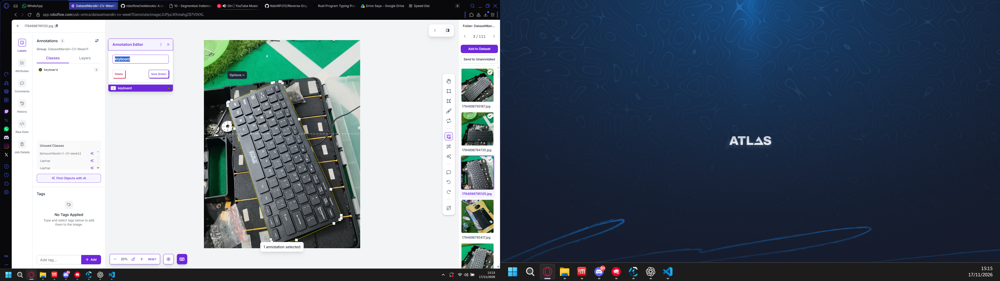

Berkas,Lebar (px),Tinggi (px),Waktu pengambilan
1794898794645.jpg,3000,4000,2026:11:17 13:49:26
1794898794735.jpg,3000,4000,2026:11:17 13:49:24
1794898794799.jpg,3000,4000,2026:11:17 13:49:21
1794898794930.jpg,3000,4000,2026:11:17 13:49:17
1794898795019.jpg,3000,4000,2026:11:17 13:49:15


Berkas,Kondisi
1794898795664.jpg,sudut miring ekstrem
1794898795697.jpg,sudut miring ekstrem
1794898795743.jpg,sudut miring ekstrem
1794898795782.jpg,sudut miring ekstrem
1794898795815.jpg,sudut miring ekstrem
1794898795856.jpg,sudut miring ekstrem
1794898795894.jpg,sudut miring ekstrem
1794898795929.jpg,sudut miring ekstrem
1794898795963.jpg,sudut miring ekstrem
1794898795998.jpg,sudut miring ekstrem


113 foto punya waktu pengambilan. Jumlah foto dengan model kamera di EXIF: 0.


In [3]:
display(DisplayImage(filename=str(EVIDENCE / 'roboflow.png'), width=1100))
metadata = pd.read_csv(EVIDENCE / 'metadata_foto_asli.csv')
display(metadata[['filename','width','height','DateTimeOriginal']].head().set_axis(['Berkas','Lebar (px)','Tinggi (px)','Waktu pengambilan'], axis=1))
ringkasan = read(EVIDENCE / 'metadata_summary.json')
print(f"{ringkasan['with_capture_time']} foto punya waktu pengambilan. Jumlah foto dengan model kamera di EXIF: {ringkasan['with_camera_model']}.")
sulit = pd.read_csv(EVIDENCE / 'kondisi_sulit.csv')
display(sulit[['filename','condition']].set_axis(['Berkas','Kondisi'], axis=1))

Pada sepuluh foto di atas, laptop terlihat dari samping atau dari atas sampai layar atau bodinya tampak sangat sempit. Foto-foto ini dipilih berdasarkan tampilan gambar. Sudut pengambilan tidak diukur. Beberapa foto memperlihatkan laptop yang sama.

## Catatan training dan grafik loss

In [4]:
completion=[]
training_logs={}
for folder in sorted((HERE/'runs').iterdir()):
    timing=read(folder/'training_time.json')
    log=pd.read_csv(folder/'results.csv');log.columns=log.columns.str.strip()
    training_logs[folder.name]=log
    completion.append({'run':folder.name,'final_epoch':int(log['epoch'].iloc[-1]),'completed':len(log) == timing['epochs'],'training_validation_minutes':timing['elapsed_seconds']/60,'peak_CUDA_allocated_GiB':timing['peak_allocated_bytes']/1024**3})
completion=pd.DataFrame(completion)
assert len(completion)==9 and completion['completed'].all() and (completion['final_epoch']==50).all()
display(completion.replace({'completed': {True: 'Ya', False: 'Belum'}}).rename(columns={'run': 'Percobaan', 'final_epoch': 'Epoch terakhir', 'completed': 'Selesai', 'training_validation_minutes': 'Latih dan validasi (menit)', 'peak_CUDA_allocated_GiB': 'Memori puncak (GiB)'}).round(3))
print('Total waktu pelatihan dan validasi:',round(completion['training_validation_minutes'].sum(),1),'menit')

Percobaan,Epoch terakhir,Selesai,Latih dan validasi (menit),Memori puncak (GiB)
maskrcnn_resnet50_fpn_320,50,Ya,32.316,0.973
maskrcnn_resnet50_fpn_640,50,Ya,44.270,1.294
maskrcnn_resnet50_fpn_960,50,Ya,69.326,2.005
yolov8n-seg_320,50,Ya,14.561,0.289
yolov8n-seg_640,50,Ya,15.255,0.719
yolov8n-seg_960,50,Ya,21.811,1.486
yolov8s-seg_320,50,Ya,12.328,0.648
yolov8s-seg_640,50,Ya,16.523,1.233
yolov8s-seg_960,50,Ya,27.099,2.088


Total waktu pelatihan dan validasi: 253.5 menit


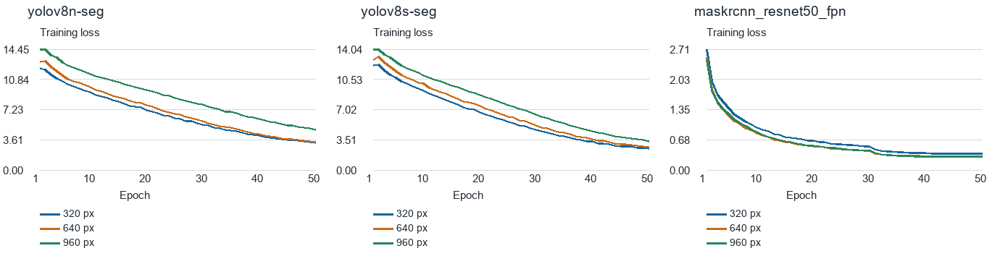

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for ax,model in zip(axes,MODELS):
    for size in SIZES:
        log=training_logs[f'{model}_{size}']
        loss=log[['train/box_loss','train/seg_loss','train/cls_loss','train/dfl_loss']].sum(axis=1) if model.startswith('yolo') else log['loss']
        ax.plot(log['epoch'],loss,label=str(size))
    ax.set(title=model,xlabel='Epoch',ylabel='Training loss')
    ax.legend(title='Ukuran (px)');ax.grid(alpha=.25)
plt.show()

Training loss menunjukkan seberapa jauh prediksi model dari anotasi saat training. Pada grafik YOLO, saya menjumlahkan empat komponen loss. Mask R-CNN menghitung loss dengan rumus berbeda, jadi saya membandingkan kurva 320, 640, dan 960 pada masing-masing model.

## Pengaruh ukuran masukan

Tabel dan grafik menampilkan AP mask dalam persen. Selisihnya dihitung dari AP foto mandiri dikurangi AP data uji asli untuk kelas laptop dan bantal. Nilai positif berarti skor pada foto mandiri lebih tinggi. Kolom memori menunjukkan alokasi CUDA tertinggi selama pelatihan.

In [6]:
comparison=pd.read_csv(HERE/'comparison.csv')
assert len(comparison)==9
result_table=comparison.copy()
for column in ['original_all_AP','original_shared_AP','personal_shared_AP']:
    result_table[column]*=100
display(result_table.rename(columns={'model': 'Model', 'input_size': 'Ukuran (px)', 'original_all_AP': 'AP asli semua kelas (%)', 'original_shared_AP': 'AP asli dua kelas (%)', 'personal_shared_AP': 'AP mandiri dua kelas (%)', 'domain_shift_AP_points': 'Selisih (poin AP)', 'elapsed_minutes': 'Waktu (menit)', 'peak_vram_GiB': 'Memori puncak (GiB)', 'latency_original_ms': 'Waktu per foto asli (ms)', 'latency_personal_ms': 'Waktu per foto mandiri (ms)'}).round(3))

Model,Ukuran (px),AP asli semua kelas (%),AP asli dua kelas (%),AP mandiri dua kelas (%),Selisih (poin AP),Waktu (menit),Memori puncak (GiB),Waktu per foto asli (ms),Waktu per foto mandiri (ms)
maskrcnn_resnet50_fpn,320,5.694,8.248,21.320,13.072,32.316,0.973,88.049,86.982
maskrcnn_resnet50_fpn,640,8.430,12.102,32.990,20.888,44.270,1.294,138.532,145.895
maskrcnn_resnet50_fpn,960,8.081,14.382,31.605,17.222,69.326,2.005,173.858,176.798
yolov8n-seg,320,0.507,0.000,0.672,0.672,14.561,0.289,13.025,12.690
yolov8n-seg,640,0.592,0.019,0.043,0.025,15.255,0.719,23.356,22.801
yolov8n-seg,960,0.473,1.446,0.000,-1.446,21.811,1.486,36.532,35.843
yolov8s-seg,320,1.148,0.891,0.000,-0.891,12.328,0.648,12.321,12.575
yolov8s-seg,640,0.844,1.600,0.056,-1.543,16.523,1.233,23.415,24.086
yolov8s-seg,960,0.518,0.471,0.000,-0.471,27.099,2.088,43.765,42.671


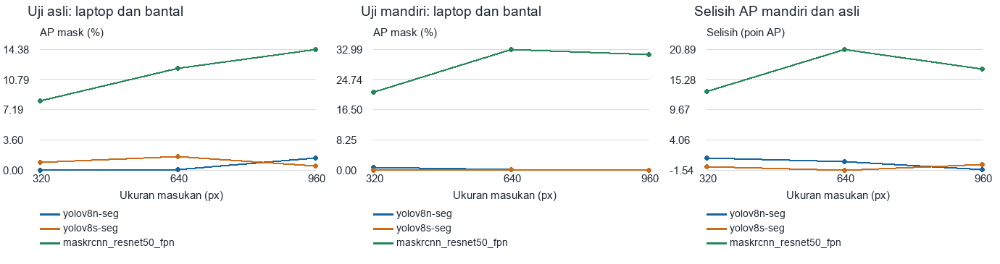

In [7]:
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for model,group in comparison.groupby('model'):
    group=group.sort_values('input_size')
    axes[0].plot(group['input_size'],100*group['original_shared_AP'],marker='o',label=model)
    axes[1].plot(group['input_size'],100*group['personal_shared_AP'],marker='o',label=model)
    axes[2].plot(group['input_size'],group['domain_shift_AP_points'],marker='o',label=model)
for ax,title,ylabel in zip(axes,['Uji asli: laptop dan bantal','Uji mandiri: laptop dan bantal','Selisih AP mandiri dan asli'],['AP mask (%)','AP mask (%)','Selisih (poin AP)']):
    ax.set(title=title,xlabel='Ukuran masukan (px)',ylabel=ylabel,xticks=list(SIZES));ax.grid(alpha=.25)
axes[2].axhline(0,color='black',linewidth=.8)
axes[0].legend(fontsize=8)
plt.show()

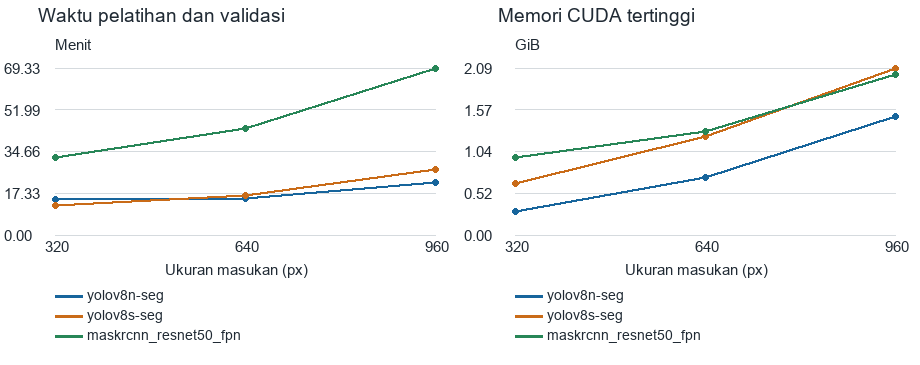

In [8]:
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for model,group in comparison.groupby('model'):
    group=group.sort_values('input_size')
    axes[0].plot(group['input_size'],group['elapsed_minutes'],marker='o',label=model)
    axes[1].plot(group['input_size'],group['peak_vram_GiB'],marker='o',label=model)
axes[0].set(title='Waktu pelatihan dan validasi',xlabel='Ukuran (px)',ylabel='Menit')
axes[1].set(title='Memori CUDA tertinggi',xlabel='Ukuran (px)',ylabel='GiB')
for ax in axes:ax.set_xticks(list(SIZES));ax.grid(alpha=.25)
axes[0].legend(fontsize=8)
plt.show()

In [9]:
best=comparison.loc[comparison['personal_shared_AP'].idxmax()]
print(f"AP mandiri tertinggi: {best['model']} pada ukuran {int(best['input_size'])}, AP {100*best['personal_shared_AP']:.2f}%")
print(f"AP asli untuk kedua kelas: {100*best['original_shared_AP']:.2f}%. Selisih {best['domain_shift_AP_points']:+.2f} poin")
per_class=[]
for folder in sorted((HERE/'runs').iterdir()):
    a=read(folder/'test_metrics.json')['common_2']['per_class_AP']
    b=read(folder/'personal_metrics.json')['all_annotated']['per_class_AP']
    for name in ['laptop','pillow']:
        per_class.append({'run':folder.name,'class':name,'original_AP_percent':None if a[name] is None else 100*a[name],'personal_AP_percent':None if b[name] is None else 100*b[name]})
display(pd.DataFrame(per_class).replace({'class': {'pillow': 'bantal'}}).rename(columns={'run': 'Percobaan', 'class': 'Kelas', 'original_AP_percent': 'AP asli (%)', 'personal_AP_percent': 'AP mandiri (%)'}).round(3))

Percobaan,Kelas,AP asli (%),AP mandiri (%)
maskrcnn_resnet50_fpn_320,laptop,14.871,16.287
maskrcnn_resnet50_fpn_320,bantal,1.625,26.352
maskrcnn_resnet50_fpn_640,laptop,21.528,31.618
maskrcnn_resnet50_fpn_640,bantal,2.676,34.362
maskrcnn_resnet50_fpn_960,laptop,25.641,25.037
maskrcnn_resnet50_fpn_960,bantal,3.124,38.172
yolov8n-seg_320,laptop,0.000,0.057
yolov8n-seg_320,bantal,0.000,1.287
yolov8n-seg_640,laptop,0.000,0.000
yolov8n-seg_640,bantal,0.037,0.087


AP mandiri tertinggi: maskrcnn_resnet50_fpn pada ukuran 640, AP 32.99%
AP asli untuk kedua kelas: 12.10%. Selisih +20.89 poin


### Hasil pada foto mandiri

Mask R-CNN mendapat AP **32,99%** pada ukuran 640. Saat ukurannya naik ke 960, AP justru turun menjadi **31,60%**, sementara waktu pelatihan dan pemakaian memori bertambah. Pada ukuran 640, AP untuk laptop dan bantal di data uji asli hanya **12,10%**. Salah satu kemungkinan penyebab selisih ini adalah beberapa objek dan latar yang sama muncul berulang kali di foto mandiri.

Kedua model YOLO mendapat AP rendah. Saya belum bisa memastikan penyebabnya dari tabel ini. Pemetaan kelas, contoh prediksi, dan jumlah contoh latih per kelas perlu diperiksa. Ketiga model juga hanya dilatih dengan satu nilai benih acak dan aturan pemilihan bobot terbaiknya berbeda.

## Lima foto yang sulit dikenali YOLO

Saya memilih lima foto dengan IoU rendah pada YOLOv8n-seg yang dilatih di ukuran 640. IoU mengukur seberapa besar mask prediksi bertumpang tindih dengan anotasi. Di sini, hanya prediksi dengan kelas yang benar yang dihitung. Kalau laptop diberi label kelas lain, nilainya tetap nol meskipun mask mengenai laptop. Untuk melihat kasus satu per satu, saya memakai ambang keyakinan 0,25. Saat menghitung AP, ambangnya 0,001.

Saya menguji kelima foto lagi pada ukuran 320 dan 960 dengan bobot model yang sama. Tujuannya untuk melihat apakah detail yang lebih jelas pada masukan besar membantu model. Uji ini belum bisa memisahkan pengaruh pembentukan mask dari kesalahan klasifikasi atau penyaringan prediksi. Pada setiap gambar di bawah, urutannya dari kiri adalah foto, anotasi saya, lalu prediksi model.

In [10]:
kasus = pd.read_csv(HERE / 'failure_analysis/measurements.csv')
assert len(kasus) == 5
kasus['Objek'] = kasus['category_id'].map({30: 'Laptop', 40: 'Bantal'})
display(kasus[['case','file','Objek','failure','IoU_640','IoU_320_same_checkpoint','IoU_960_same_checkpoint']].set_axis(['Foto','Berkas','Objek','Kesalahan','IoU 640','IoU 320','IoU 960'], axis=1))

Foto,Berkas,Objek,Kesalahan,IoU 640,IoU 320,IoU 960
1,1794898796166_jpg.rf.02c2d8709d92f069802076f499...,Laptop,salah kelas,0.0,0.0,0.0
2,1794898795266_jpg.rf.040903773294916a5f09ffc929...,Laptop,salah kelas,0.0,0.0,0.0
3,1794898795530_jpg.rf.ff87061cdfdbf145a651e89dc2...,Laptop,salah kelas,0.0,0.0,0.0
4,1794899111511_jpg.rf.4b825f48a8774879daa77a1d5e...,Bantal,salah kelas,0.0,0.0,0.0
5,1794899111555_jpg.rf.ed5181fe46bb1f7daaa3e155a5...,Bantal,tidak ada prediksi kelas benar pada skor >=0.25,0.0,0.0,0.0


### Foto 1 · Laptop

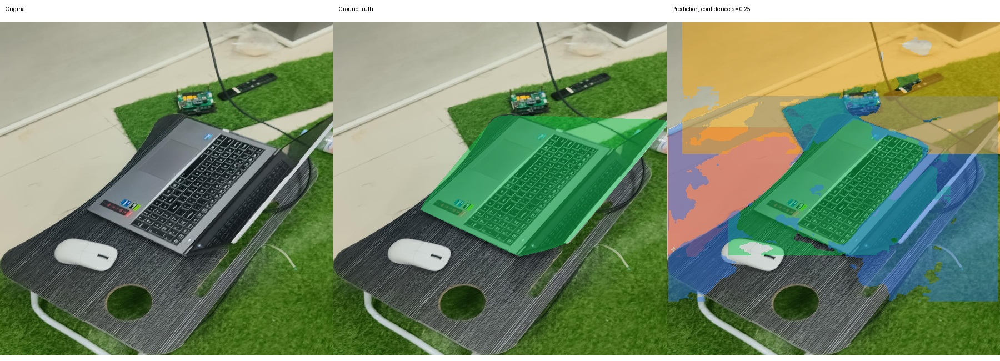

In [11]:
display(DisplayImage(filename=str(HERE/'failure_analysis/case_1.jpg'),width=1200))

### Foto 2 · Laptop

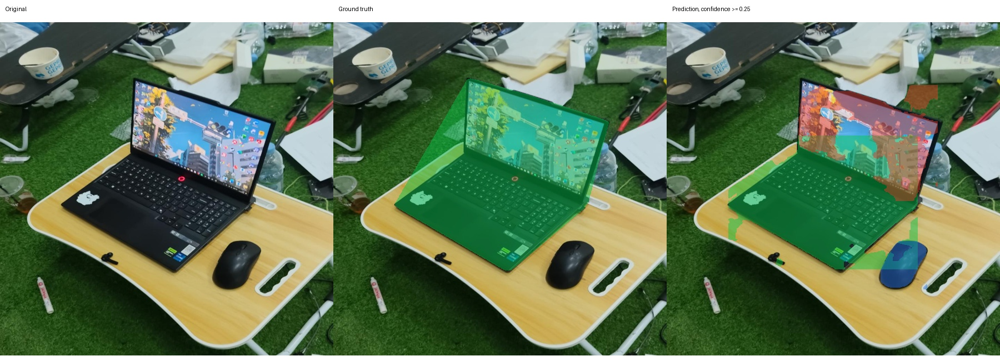

In [12]:
display(DisplayImage(filename=str(HERE/'failure_analysis/case_2.jpg'),width=1200))

### Foto 3 · Laptop

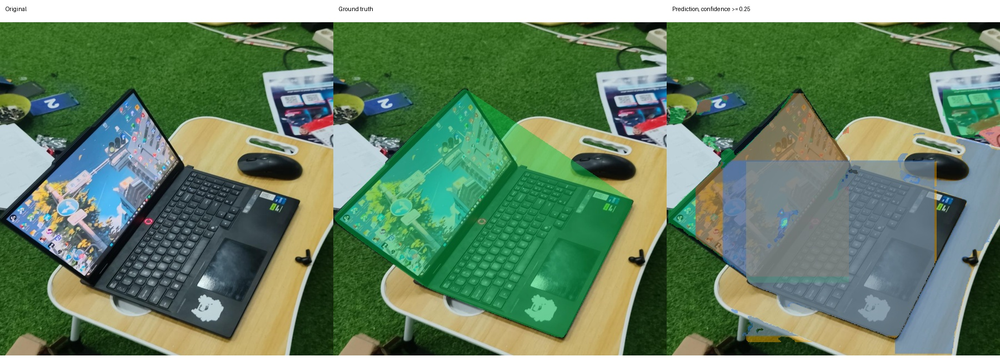

In [13]:
display(DisplayImage(filename=str(HERE/'failure_analysis/case_3.jpg'),width=1200))

### Foto 4 · Bantal

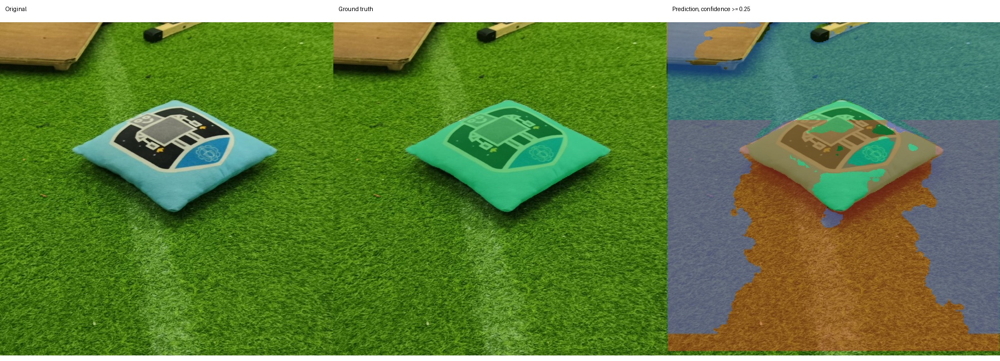

In [14]:
display(DisplayImage(filename=str(HERE/'failure_analysis/case_4.jpg'),width=1200))

### Foto 5 · Bantal

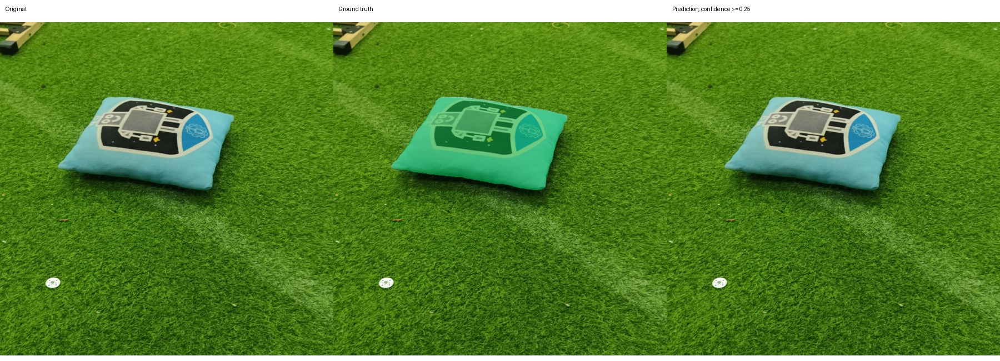

In [15]:
display(DisplayImage(filename=str(HERE/'failure_analysis/case_5.jpg'),width=1200))

Pada tiga foto laptop dan satu foto bantal, model memberi label kelas yang salah. Pada foto bantal terakhir, tidak ada prediksi kelas bantal yang lolos ambang 0,25. Di kelima foto, IoU untuk kelas yang benar tetap nol saat ukuran masukan diubah dari 320 ke 960.

## Kesimpulan

Dari sembilan percobaan, Mask R-CNN pada ukuran 640 memberi hasil terbaik untuk foto laptop dan bantal saya. Menambah ukuran menjadi 960 memakan lebih banyak waktu dan memori tanpa memperbaiki AP mandiri. Pada lima foto yang gagal dikenali YOLO, memperbesar gambar saat pengujian juga belum membantu.

Hasil ini terbatas pada koleksi foto saya. Beberapa objek dan latar muncul berulang, dan bentuk objek bisa berubah setelah foto ditarik menjadi persegi. Di dataset asli, jumlah contoh antarkelas juga timpang, bahkan ada kelas tanpa contoh latih.

## Referensi

- [Segmentasi instance dengan Ultralytics](https://docs.ultralytics.com/tasks/segment/)
- [Mask R-CNN di Torchvision](https://docs.pytorch.org/vision/0.22/models/generated/torchvision.models.detection.maskrcnn_resnet50_fpn.html)
- [Evaluasi COCO dengan Python](https://github.com/cocodataset/cocoapi/tree/master/PythonAPI/pycocotools)